<a href="https://colab.research.google.com/github/PreethiR091/Deep-Learning/blob/main/Preethi_R_24BAD091_DL_Ex_no_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXPT NO: 5 - IMPLEMENTATION OF A RECURRENT NEURAL NETWORK (RNN) FOR TEXT GENERATION

TASK A: DATASET PREPARATION

Perform the following tasks:

    •	Load the Tiny Shakespeare dataset from Hugging Face.
    •	Explore the dataset and examine the text samples.
    •	Convert the text into lowercase (if required).
    •	Tokenize the text into individual words.
    •	Build a vocabulary and assign a unique integer index to each word.
    •	Generate input sequences for next-word prediction.
    •	Apply sequence padding to obtain inputs of equal length.
    •	Split the prepared sequences into training and validation datasets.



In [ ]:
# EXPERIMENT NO: 5
# TASK A: DATASET PREPARATION
# Student Name: Preethi R
# Roll No: 24BAD091

print("Preethi R - 24BAD091\n")

!pip install -q datasets

import numpy as np
from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Load Tiny Shakespeare dataset from Hugging Face

dataset = load_dataset("Trelis/tiny-shakespeare")

print("\nDataset loaded successfully.")
print(dataset)

# 2. Explore the dataset

print("\nDataset splits:")
print(dataset.keys())

split_name = "train"

print("\nDataset columns:")
print(dataset[split_name].column_names)

print("\nFirst dataset sample:")
print(dataset[split_name][0])

# 3. Extract the text

text = " ".join(dataset[split_name]["Text"])

print("\nFirst 1000 characters of the text:")
print(text[:1000])

# 4. Convert text to lowercase

text = text.lower()

print("\nText converted to lowercase successfully.")

# 5. Tokenize the text into individual words

tokenizer = Tokenizer(
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
)

tokenizer.fit_on_texts([text])

tokenized_text = tokenizer.texts_to_sequences([text])[0]

vocab_size = len(tokenizer.word_index) + 1

print("\nVocabulary size:", vocab_size)

print("\nSample vocabulary:")
for word, index in list(tokenizer.word_index.items())[:20]:
    print(word, ":", index)

# 6. Generate input sequences for next-word prediction

sequence_length = 20

input_sequences = []

for i in range(sequence_length, len(tokenized_text)):
    sequence = tokenized_text[i - sequence_length:i + 1]
    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

print("\nNumber of generated sequences:", len(input_sequences))
print("Sequence shape:", input_sequences.shape)

# 7. Apply sequence padding

padded_sequences = pad_sequences(
    input_sequences,
    maxlen=sequence_length + 1,
    padding="pre"
)

print("\nPadded sequence shape:", padded_sequences.shape)

# 8. Separate input and target

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

# 9. Split into training and validation datasets

split_index = int(0.9 * len(X))

X_train = X[:split_index]
y_train = y[:split_index]

X_val = X[split_index:]
y_val = y[split_index:]

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))

print("\nTraining input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("Validation input shape:", X_val.shape)
print("Validation target shape:", y_val.shape)

print("\nTASK A COMPLETED SUCCESSFULLY")
print("Vocabulary Size:", vocab_size)
print("Sequence Length:", sequence_length)
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))



Preethi R - 24BAD091


Dataset loaded successfully.
DatasetDict({
    train: Dataset({
        features: ['Text'],
        num_rows: 472
    })
    test: Dataset({
        features: ['Text'],
        num_rows: 49
    })
})

Dataset splits:
dict_keys(['train', 'test'])

Dataset columns:
['Text']

First dataset sample:
{'Text': "First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are all resolved rather to die than to famish?\n\nAll:\nResolved. resolved.\n\nFirst Citizen:\nFirst, you know Caius Marcius is chief enemy to the people.\n\nAll:\nWe know't, we know't.\n\nFirst Citizen:\nLet us kill him, and we'll have corn at our own price.\nIs't a verdict?\n\nAll:\nNo more talking on't; let it be done: away, away!\n\nSecond Citizen:\nOne word, good citizens.\n\nFirst Citizen:\nWe are accounted poor citizens, the patricians good.\nWhat authority surfeits on would relieve us: if they\nwould yield us but the superfluity, while it were\nwhol

TASK B: IMPLEMENTING THE RNN MODEL

Perform the following tasks:

    •	Create an Embedding layer to convert words into dense vector representations.
    •	Add a Simple RNN layer to learn sequential dependencies in the text.
    •	Add a Dense output layer with Softmax activation for next-word prediction.
    •	Compile the model using an appropriate optimizer and loss function.
    •	Display the model architecture and summary.


In [ ]:
# EXPERIMENT NO: 5
# TASK B: IMPLEMENTING THE RNN MODEL
# Student Name: Preethi R
# Roll No: 24BAD091

print("Preethi R - 24BAD091\n")

!pip install -q datasets

from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# 1. Load Tiny Shakespeare dataset

dataset = load_dataset("Trelis/tiny-shakespeare")

split_name = "train"

text = " ".join(dataset[split_name]["Text"])

text = text.lower()

print("Dataset loaded successfully.")

# 2. Tokenize the text

tokenizer = Tokenizer(
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
)

tokenizer.fit_on_texts([text])

tokenized_text = tokenizer.texts_to_sequences([text])[0]

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)

# 3. Generate input sequences

sequence_length = 20

input_sequences = []

for i in range(sequence_length, len(tokenized_text)):
    sequence = tokenized_text[i - sequence_length:i + 1]
    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

# 4. Apply padding

padded_sequences = pad_sequences(
    input_sequences,
    maxlen=sequence_length + 1,
    padding="pre"
)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

# 5. Create the RNN model

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        input_length=sequence_length
    ),
    SimpleRNN(128),
    Dense(vocab_size, activation="softmax")
])

# 6. Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nModel compiled successfully.")

# 7. Display model architecture

print("\nRNN MODEL ARCHITECTURE")

model.summary()

print("\nTASK B COMPLETED SUCCESSFULLY")
print("Architecture: Embedding → SimpleRNN → Dense")


Preethi R - 24BAD091

Dataset loaded successfully.
Vocabulary Size: 11981
Input Shape: (223866, 20)
Target Shape: (223866,)

Model compiled successfully.

RNN MODEL ARCHITECTURE


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


TASK B COMPLETED SUCCESSFULLY
Architecture: Embedding → SimpleRNN → Dense


TASK C: RNN MODEL TRAINING AND PERFORMANCE EVALUATION

Perform the following tasks:

    •	Train the RNN model using the prepared training dataset.
    •	Validate the model using the validation dataset.
    •	Record:
          o	Training accuracy
          o	Validation accuracy
          o	Training loss
          o	Validation loss
    •	Visualize:
          o	Accuracy vs. Epoch
          o	Loss vs. Epoch


Preethi R - 24BAD091

Dataset loaded successfully.
Vocabulary Size: 11981

Training samples: 201479
Validation samples: 22387

Starting model training...

Epoch 1/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 174s 109ms/step - accuracy: 0.0465 - loss: 6.7524 - val_accuracy: 0.0615 - val_loss: 6.6572
Epoch 2/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 160s 102ms/step - accuracy: 0.0852 - loss: 6.0863 - val_accuracy: 0.0796 - val_loss: 6.5523
Epoch 3/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 160s 102ms/step - accuracy: 0.1037 - loss: 5.7009 - val_accuracy: 0.0836 - val_loss: 6.6017
Epoch 4/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 207s 104ms/step - accuracy: 0.1216 - loss: 5.3587 - val_accuracy: 0.0857 - val_loss: 6.6281
Epoch 5/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 163s 104ms/step - accuracy: 0.1414 - loss: 5.0317 - val_accuracy: 0.0860 - val_loss: 6.7718
Epoch 6/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 199s 102ms/step - accuracy: 0.1676 - loss: 4.7209 - val_accuracy: 0.0854 - val_loss: 6.9222
Epoch 7/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━

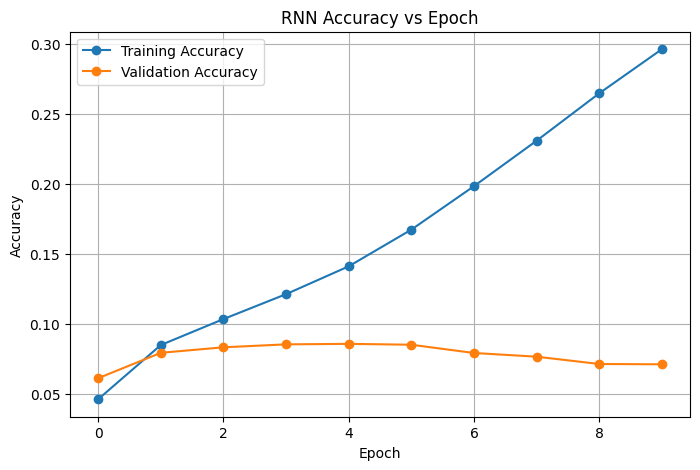

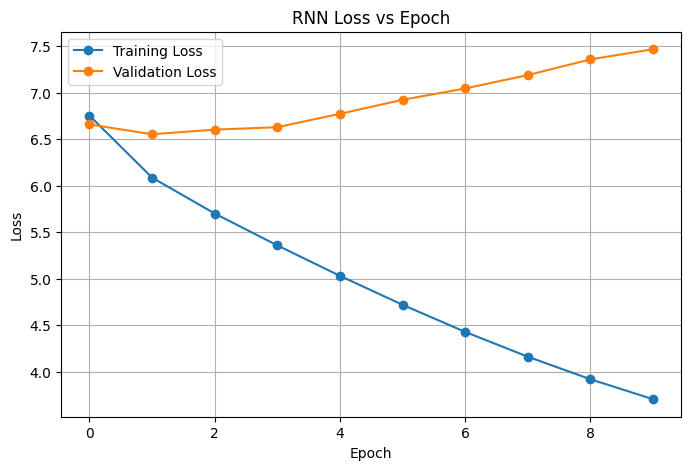


TASK C COMPLETED SUCCESSFULLY


In [ ]:
# EXPERIMENT NO: 5
# TASK C: RNN MODEL TRAINING AND PERFORMANCE EVALUATION
# Student Name: Preethi R
# Roll No: 24BAD091

print("Preethi R - 24BAD091\n")

!pip install -q datasets

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# 1. Load Tiny Shakespeare dataset

dataset = load_dataset("Trelis/tiny-shakespeare")

split_name = "train"

text = " ".join(dataset[split_name]["Text"])

text = text.lower()

print("Dataset loaded successfully.")

# 2. Tokenize the text

tokenizer = Tokenizer(
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
)

tokenizer.fit_on_texts([text])

tokenized_text = tokenizer.texts_to_sequences([text])[0]

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)

# 3. Generate input sequences

sequence_length = 20

input_sequences = []

for i in range(sequence_length, len(tokenized_text)):
    sequence = tokenized_text[i - sequence_length:i + 1]
    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

# 4. Apply sequence padding

padded_sequences = pad_sequences(
    input_sequences,
    maxlen=sequence_length + 1,
    padding="pre"
)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

# 5. Split into training and validation datasets

split_index = int(0.9 * len(X))

X_train = X[:split_index]
y_train = y[:split_index]

X_val = X[split_index:]
y_val = y[split_index:]

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))

# 6. Create the RNN model

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        input_length=sequence_length
    ),
    SimpleRNN(128),
    Dense(vocab_size, activation="softmax")
])

# 7. Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 8. Train the RNN model

print("\nStarting model training...\n")

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

# 9. Record performance

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

print("\nFINAL PERFORMANCE RESULTS")

print("Training Accuracy   :", f"{train_accuracy[-1]:.4f}")
print("Validation Accuracy :", f"{val_accuracy[-1]:.4f}")
print("Training Loss       :", f"{train_loss[-1]:.4f}")
print("Validation Loss     :", f"{val_loss[-1]:.4f}")

# 10. Accuracy vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracy,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    val_accuracy,
    marker="o",
    label="Validation Accuracy"
)

plt.title("RNN Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 11. Loss vs Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    val_loss,
    marker="o",
    label="Validation Loss"
)

plt.title("RNN Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

print("\nTASK C COMPLETED SUCCESSFULLY")

TASK D: DEEP LEARNING EXPERIMENT MANAGEMENT

Perform the following tasks:

    •	Provide a seed word or sentence as input to the trained model.
    •	Generate text by repeatedly predicting the next word in the sequence.
    •	Produce multiple text samples using different seed inputs.
    •	Compare the generated text for coherence and contextual relevance.
    •	Document the observations and upload the notebook to GitHub.


In [ ]:
# EXPERIMENT NO: 5
# TASK D: DEEP LEARNING EXPERIMENT MANAGEMENT
# Student Name: Preethi R
# Roll No: 24BAD091

print("Preethi R - 24BAD091\n")

!pip install -q datasets

import numpy as np
import tensorflow as tf

from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# 1. Load Tiny Shakespeare dataset

dataset = load_dataset("Trelis/tiny-shakespeare")

split_name = "train"

text = " ".join(dataset[split_name]["Text"])

text = text.lower()

print("Dataset loaded successfully.")

# 2. Tokenize the text

tokenizer = Tokenizer(
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n'
)

tokenizer.fit_on_texts([text])

tokenized_text = tokenizer.texts_to_sequences([text])[0]

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary Size:", vocab_size)

# 3. Generate input sequences

sequence_length = 20

input_sequences = []

for i in range(sequence_length, len(tokenized_text)):
    sequence = tokenized_text[i - sequence_length:i + 1]
    input_sequences.append(sequence)

input_sequences = np.array(input_sequences)

# 4. Apply padding

padded_sequences = pad_sequences(
    input_sequences,
    maxlen=sequence_length + 1,
    padding="pre"
)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

# 5. Split the data

split_index = int(0.9 * len(X))

X_train = X[:split_index]
y_train = y[:split_index]

X_val = X[split_index:]
y_val = y[split_index:]

# 6. Create the RNN model

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        input_length=sequence_length
    ),
    SimpleRNN(128),
    Dense(vocab_size, activation="softmax")
])

# 7. Compile the model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 8. Train the model

print("Training the RNN model...\n")

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

print("\nModel training completed.")

# 9. Create reverse vocabulary

index_to_word = {
    index: word
    for word, index in tokenizer.word_index.items()
}

# 10. Define text generation function

def generate_text(seed_text, next_words=30):

    generated_text = seed_text.lower()

    for _ in range(next_words):

        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        token_list = token_list[-sequence_length:]

        token_list = pad_sequences(
            [token_list],
            maxlen=sequence_length,
            padding="pre"
        )

        predictions = model.predict(
            token_list,
            verbose=0
        )[0]

        predicted_id = np.argmax(predictions)

        predicted_word = index_to_word.get(
            predicted_id,
            None
        )

        if predicted_word is None:
            break

        generated_text += " " + predicted_word

    return generated_text

# 11. Generate multiple text samples

seed_inputs = [
    "the king",
    "my lord",
    "love is",
    "what shall",
    "good sir"
]

print("\nGENERATED TEXT SAMPLES")

for i, seed in enumerate(seed_inputs, start=1):

    generated_text = generate_text(
        seed,
        next_words=30
    )

    print(f"\nSample {i}")
    print("Seed:", seed)
    print("Generated Text:")
    print(generated_text)

# 12. Observations

print("\nOBSERVATIONS")

print("1. The RNN predicts the next word based on the previous sequence.")
print("2. Different seed inputs produce different text sequences.")
print("3. The generated text follows patterns learned from the dataset.")
print("4. Some sequences may be meaningful while others may contain repetition.")
print("5. The Simple RNN has difficulty remembering long-term dependencies.")

print("\nTASK D COMPLETED SUCCESSFULLY")

Preethi R - 24BAD091

Dataset loaded successfully.
Vocabulary Size: 11981
Training the RNN model...

Epoch 1/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 166s 104ms/step - accuracy: 0.0548 - loss: 6.6054 - val_accuracy: 0.0722 - val_loss: 6.5456
Epoch 2/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 162s 103ms/step - accuracy: 0.0921 - loss: 5.9212 - val_accuracy: 0.0898 - val_loss: 6.4919
Epoch 3/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 201s 102ms/step - accuracy: 0.1105 - loss: 5.5209 - val_accuracy: 0.0853 - val_loss: 6.5754
Epoch 4/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 165s 105ms/step - accuracy: 0.1297 - loss: 5.1790 - val_accuracy: 0.0872 - val_loss: 6.6799
Epoch 5/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 164s 104ms/step - accuracy: 0.1519 - loss: 4.8695 - val_accuracy: 0.0817 - val_loss: 6.7850
Epoch 6/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 166s 105ms/step - accuracy: 0.1792 - loss: 4.5819 - val_accuracy: 0.0804 - val_loss: 6.9495
Epoch 7/10
1575/1575 ━━━━━━━━━━━━━━━━━━━━ 165s 105ms/step - accuracy: 0.2104 - loss: 4.3165 - v